
# Task 3: Cleaning Data

**Internship:** Oasis Infobyte — Data Analytics

## Objective
To identify and correct data quality issues in a dataset and transform it into a clean, analysis-ready dataset.

## Dataset
Titanic passenger dataset.

## Tools Used
- Python
- Pandas
- NumPy
- Jupyter Notebook

## Cleaning Process
1. Data quality assessment
2. Missing value handling
3. Duplicate removal
4. Data standardization
5. Outlier detection
6. Data type correction
7. Before-and-after comparison
8. Export cleaned data to CSV


In [1]:

import pandas as pd
import numpy as np

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load the dataset
df = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:

# Basic dataset information
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

print("\nStatistical summary:")
display(df.describe(include="all").T)


Number of rows: 891
Number of columns: 12

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [4]:

# Initial data quality report
quality_before = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Missing_Values": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2),
    "Unique_Values": df.nunique(dropna=True)
})

print("DATA QUALITY REPORT — BEFORE CLEANING")
display(quality_before)

print("Duplicate rows:", df.duplicated().sum())
print("Total rows:", len(df))


DATA QUALITY REPORT — BEFORE CLEANING


,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
PassengerId,int64,0,0.00,891
Survived,int64,0,0.00,2
Pclass,int64,0,0.00,3
Name,str,0,0.00,891
Sex,str,0,0.00,2
Age,float64,177,19.87,88
SibSp,int64,0,0.00,7
Parch,int64,0,0.00,7
Ticket,str,0,0.00,681
Fare,float64,0,0.00,248


Duplicate rows: 0
Total rows: 891


In [5]:

# Check missing values in each column
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_report[missing_report["Missing_Count"] > 0]
        .sort_values("Missing_Count", ascending=False))


,Missing_Count,Missing_Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22



## Missing Data Handling — Decisions

- **Age:** Missing values will be replaced with the median because age is numeric and may contain extreme values.
- **Embarked:** Missing values will be replaced with the mode because this is a categorical column.
- **Cabin:** This column has substantial missing data. We will drop it from the cleaned dataset if the missing percentage is very high, and document this decision.
- **Other columns:** We will inspect any remaining missing values before deciding how to handle them.

These decisions aim to preserve useful information while avoiding unnecessary data loss.


In [6]:

# Keep an original copy for comparison
df_clean = df.copy()

# Fill missing numeric Age values with the median
if "Age" in df_clean.columns and df_clean["Age"].isnull().any():
    df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

# Fill missing Embarked values with the mode
if "Embarked" in df_clean.columns and df_clean["Embarked"].isnull().any():
    embarked_mode = df_clean["Embarked"].mode()
    if not embarked_mode.empty:
        df_clean["Embarked"] = df_clean["Embarked"].fillna(embarked_mode.iloc[0])

# Drop Cabin if more than 50% of its values are missing
if "Cabin" in df_clean.columns:
    cabin_missing_pct = df_clean["Cabin"].isnull().mean() * 100
    if cabin_missing_pct > 50:
        df_clean = df_clean.drop(columns=["Cabin"])
        print(f"Cabin dropped because {cabin_missing_pct:.2f}% of values were missing.")

print("Missing-value handling completed.")
print("\nRemaining missing values:")
display(df_clean.isnull().sum().to_frame("Missing_Count"))


Cabin dropped because 77.10% of values were missing.
Missing-value handling completed.

Remaining missing values:


,Missing_Count
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [7]:

# Count duplicate rows before removal
duplicates_before = df_clean.duplicated().sum()

print("Duplicate rows before cleaning:", duplicates_before)

# Remove duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Count duplicate rows after removal
duplicates_after = df_clean.duplicated().sum()

print("Duplicate rows after cleaning:", duplicates_after)
print("Rows removed:", duplicates_before - duplicates_after)
print("Rows remaining:", len(df_clean))


Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
Rows removed: 0
Rows remaining: 891


In [9]:

# Standardize text formatting
text_columns = df_clean.select_dtypes(include=["str"]).columns

for col in text_columns:
    df_clean[col] = df_clean[col].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Standardize the Sex column
if "Sex" in df_clean.columns:
    df_clean["Sex"] = df_clean["Sex"].str.lower().str.strip()

# Standardize the Embarked column
if "Embarked" in df_clean.columns:
    df_clean["Embarked"] = df_clean["Embarked"].str.upper().str.strip()

print("Text standardization completed!")
print("\nSex values:")
print(df_clean["Sex"].value_counts())

print("\nEmbarked values:")
print(df_clean["Embarked"].value_counts())


Text standardization completed!

Sex values:
Sex
male      577
female    314
Name: count, dtype: int64

Embarked values:
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64


In [10]:

# Detect outliers using the IQR method

numeric_columns = ["Age", "SibSp", "Parch", "Fare"]
outlier_results = []

for col in numeric_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df_clean[col] < lower_limit) |
        (df_clean[col] > upper_limit)
    ).sum()

    outlier_results.append({
        "Column": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "Lower Limit": round(lower_limit, 2),
        "Upper Limit": round(upper_limit, 2),
        "Outlier Count": int(outlier_count)
    })

outlier_report = pd.DataFrame(outlier_results)

print("OUTLIER DETECTION REPORT")
display(outlier_report)


OUTLIER DETECTION REPORT


,Column,Q1,Q3,Lower Limit,Upper Limit,Outlier Count
0,Age,22.00,35.0,2.50,54.50,66
1,SibSp,0.00,1.0,-1.50,2.50,46
2,Parch,0.00,0.0,0.00,0.00,213
3,Fare,7.91,31.0,-26.72,65.63,116



## Outlier Detection and Treatment

The Interquartile Range (IQR) method was used to identify potential outliers in Age, SibSp, Parch, and Fare.

The IQR method flags values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR.

**Decision:** Potential outliers are retained at this stage because extreme values may represent genuine passenger characteristics, such as unusually high fares or large family groups. Removing valid observations could lead to information loss.

The outlier counts are documented for further analysis.


In [11]:

# Create before-and-after data quality summaries

before_summary = {
    "Rows": len(df),
    "Columns": df.shape[1],
    "Total Missing Values": int(df.isnull().sum().sum()),
    "Duplicate Rows": int(df.duplicated().sum()),
    "Numeric Columns": int(df.select_dtypes(include="number").shape[1])
}

after_summary = {
    "Rows": len(df_clean),
    "Columns": df_clean.shape[1],
    "Total Missing Values": int(df_clean.isnull().sum().sum()),
    "Duplicate Rows": int(df_clean.duplicated().sum()),
    "Numeric Columns": int(df_clean.select_dtypes(include="number").shape[1])
}

comparison = pd.DataFrame({
    "Before Cleaning": before_summary,
    "After Cleaning": after_summary
})

comparison["Change"] = (
    comparison["After Cleaning"] - comparison["Before Cleaning"]
)

print("BEFORE VS. AFTER CLEANING")
display(comparison)


BEFORE VS. AFTER CLEANING


,Before Cleaning,After Cleaning,Change
Rows,891,891,0
Columns,12,11,-1
Total Missing Values,866,0,-866
Duplicate Rows,0,0,0
Numeric Columns,7,7,0


In [12]:

print("FINAL DATA QUALITY CHECK")
print("-" * 35)

print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nFinal data types:")
display(df_clean.dtypes.to_frame("Data Type"))

print("\nFirst five cleaned rows:")
display(df_clean.head())


FINAL DATA QUALITY CHECK
-----------------------------------
Dataset shape: (891, 11)
Missing values: 0
Duplicate rows: 0

Final data types:


,Data Type
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64



First five cleaned rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [13]:

# Export cleaned dataset
output_file = "titanic_cleaned.csv"

df_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("File name:", output_file)
print("Rows saved:", len(df_clean))


Cleaned dataset saved successfully!
File name: titanic_cleaned.csv
Rows saved: 891


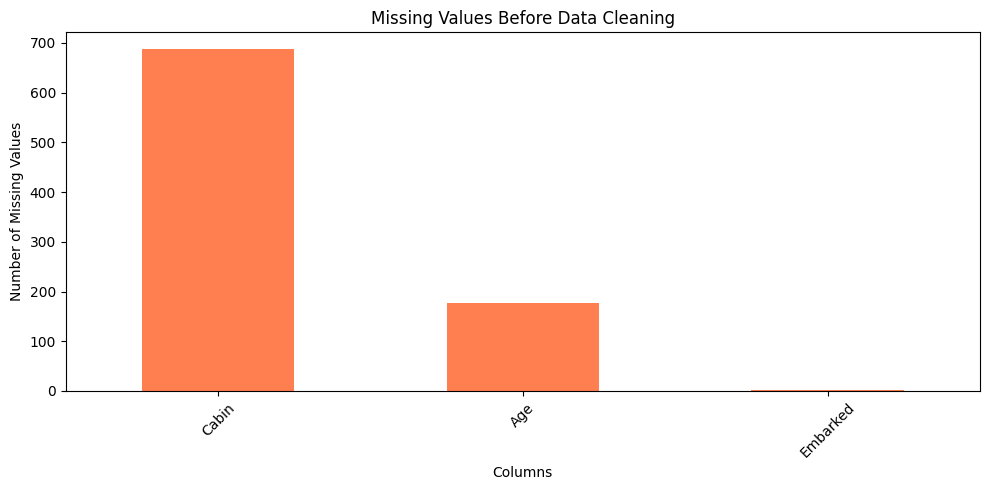

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

# Plot missing values in the original dataset
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
missing_counts.plot(kind="bar", color="coral")
plt.title("Missing Values Before Data Cleaning")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


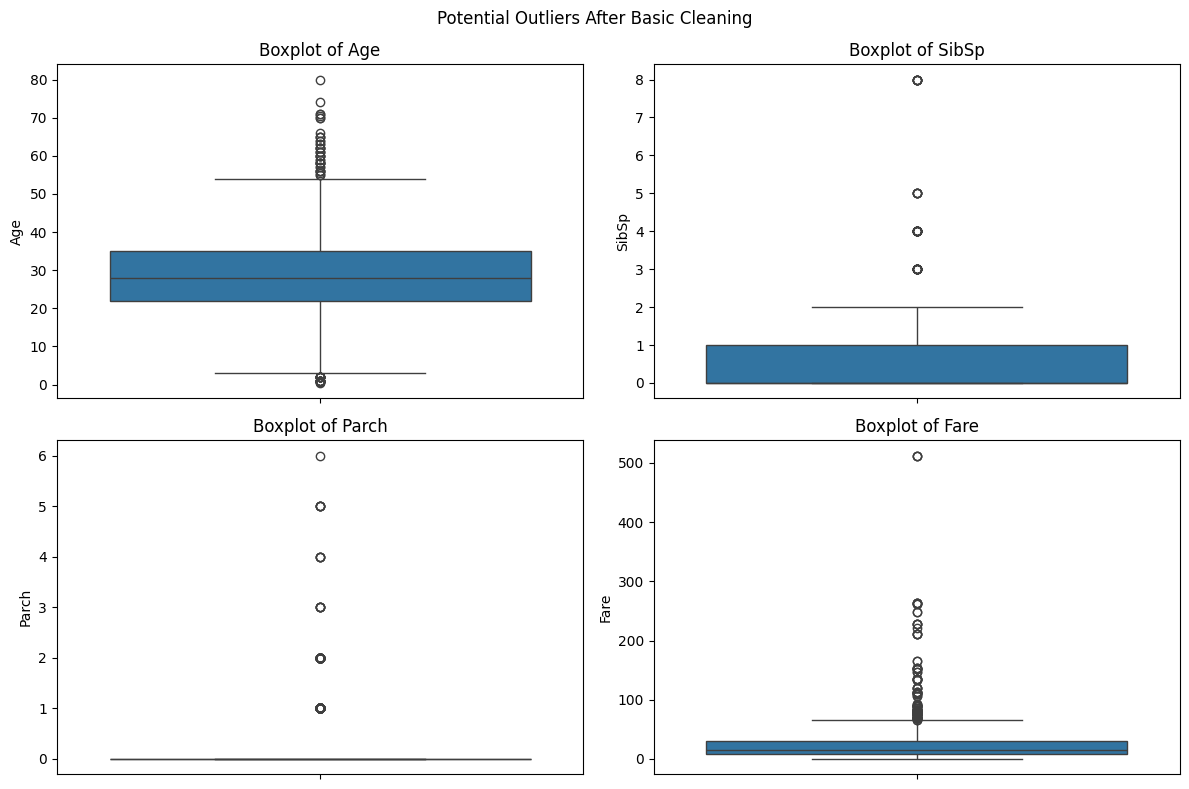

In [16]:

# Visualize potential outliers in numeric columns
numeric_columns = ["Age", "SibSp", "Parch", "Fare"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(numeric_columns, axes.flatten()):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.suptitle("Potential Outliers After Basic Cleaning")
plt.tight_layout()
plt.show()


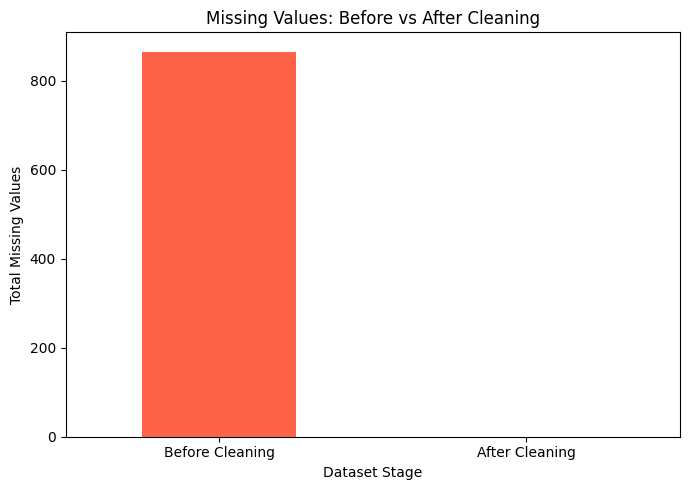

In [17]:

# Compare total missing values before and after cleaning
missing_comparison = pd.Series({
    "Before Cleaning": int(df.isnull().sum().sum()),
    "After Cleaning": int(df_clean.isnull().sum().sum())
})

plt.figure(figsize=(7, 5))
missing_comparison.plot(kind="bar", color=["tomato", "seagreen"])
plt.title("Missing Values: Before vs After Cleaning")
plt.xlabel("Dataset Stage")
plt.ylabel("Total Missing Values")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



# Conclusion

In this project, the Titanic dataset was cleaned using Python, Pandas, and NumPy.

The data quality assessment identified missing values, duplicate records, data types, and potential numeric outliers. Missing values were handled using median and mode imputation where appropriate. The Cabin column was removed because it contained a high percentage of missing values. Duplicate rows were removed, text formatting was standardized, and data types were reviewed and corrected.

The Interquartile Range (IQR) method was used to identify potential outliers. These values were retained because they may represent genuine passenger characteristics.

A before-and-after comparison was created to document the cleaning process, and the cleaned dataset was exported as a CSV file.

This project demonstrates how systematic data cleaning improves data quality and prepares a dataset for further analysis.
